# Layered (stacked) GRU — ETH-USD

Predicts the next **Close** from `ETH-USD_for_layered_GRU.csv` using a **two-layer stacked GRU**.

**Metrics:** MSE, RMSE, MAE, MAPE on the test set (USD / USD² as appropriate).  
**Confusion matrix:** 2×2 **direction** (next period up vs down vs last close) — standard for continuous price forecasts.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import confusion_matrix, mean_absolute_error, mean_squared_error

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

WINDOW = 60
EPOCHS = 100
BATCH_SIZE = 32
PATIENCE = 15
RANDOM_SEED = 42

np.random.seed(RANDOM_SEED)
tf.random.set_seed(RANDOM_SEED)

_cwd = Path.cwd().resolve()
if (_cwd / "ETH-USD_for_layered_GRU.csv").exists():
    CSV_PATH = _cwd / "ETH-USD_for_layered_GRU.csv"
elif (_cwd / "Layered GRU" / "ETH-USD_for_layered_GRU.csv").exists():
    CSV_PATH = _cwd / "Layered GRU" / "ETH-USD_for_layered_GRU.csv"
else:
    CSV_PATH = _cwd.parent / "Layered GRU" / "ETH-USD_for_layered_GRU.csv"
CSV_PATH = str(CSV_PATH)
print("Using:", CSV_PATH)

Using: /Users/rishinatarajan/ACM Folder/ACM Research ForeQast/ForeQast/Layered GRU/ETH-USD_for_layered_GRU.csv


In [2]:
df = pd.read_csv(CSV_PATH, parse_dates=["Date"])
df = df.sort_values("Date").reset_index(drop=True)
df.head()

,Date,Open,High,Low,Close,Adj Close,Volume
0,2017-11-09,308.644989,329.451996,307.056000,320.884003,320.884003,893249984
1,2017-11-10,320.670990,324.717987,294.541992,299.252991,299.252991,885985984
2,2017-11-11,298.585999,319.453003,298.191986,314.681000,314.681000,842300992
3,2017-11-12,314.690002,319.153015,298.513000,307.907990,307.907990,1613479936
4,2017-11-13,307.024994,328.415009,307.024994,316.716003,316.716003,1041889984


In [3]:
close_values = df["Close"].values.reshape(-1, 1)

n = len(close_values)
train_end = int(n * 0.80)
val_end = int(n * 0.85)

train_raw = close_values[:train_end]
val_raw = close_values[train_end:val_end]
test_raw = close_values[val_end:]

scaler = MinMaxScaler()
train = scaler.fit_transform(train_raw)
val = scaler.transform(val_raw)
test = scaler.transform(test_raw)

train.shape, val.shape, test.shape

((1278, 1), (80, 1), (240, 1))

In [4]:
def make_windows(data, window=WINDOW):
    X, y = [], []
    for i in range(window, len(data)):
        X.append(data[i - window : i])
        y.append(data[i, 0])
    return np.array(X), np.array(y).reshape(-1, 1)


X_train, y_train = make_windows(train, WINDOW)
X_val, y_val = make_windows(val, WINDOW)
X_test, y_test = make_windows(test, WINDOW)

val_end_idx = int(len(df) * 0.85)
test_start = val_end_idx
last_close_test = np.array(
    [df["Close"].iloc[test_start + WINDOW + k - 1] for k in range(len(y_test))],
    dtype=np.float64,
).reshape(-1, 1)

X_train.shape, X_test.shape

((1218, 60, 1), (180, 60, 1))

In [5]:
model = keras.Sequential(
    [
        layers.Input(shape=(WINDOW, 1)),
        layers.GRU(128, return_sequences=True),
        layers.Dropout(0.2),
        layers.GRU(64, return_sequences=False),
        layers.Dropout(0.2),
        layers.Dense(16, activation="relu"),
        layers.Dense(1),
    ]
)
model.compile(optimizer="adam", loss="mse", metrics=["mae"])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ gru (GRU)                       │ (None, 60, 128)        │        50,304 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 60, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru_1 (GRU)                     │ (None, 64)             │        37,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 16)             │         1,040 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 88,609 (346.13 KB)

 Trainable params: 88,609 (346.13 KB)

 Non-trainable params: 0 (0.00 B)

In [6]:
early = keras.callbacks.EarlyStopping(
    monitor="val_loss", patience=PATIENCE, restore_best_weights=True
)
history = model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=[early],
    verbose=1,
)
print(f"Training stopped at epoch {len(history.history['loss'])}")

Epoch 1/100
39/39 ━━━━━━━━━━━━━━━━━━━━ 2s 33ms/step - loss: 0.0029 - mae: 0.0336 - val_loss: 0.0043 - val_mae: 0.0544
Epoch 2/100
39/39 ━━━━━━━━━━━━━━━━━━━━ 1s 30ms/step - loss: 0.0011 - mae: 0.0205 - val_loss: 0.0013 - val_mae: 0.0329
Epoch 3/100
39/39 ━━━━━━━━━━━━━━━━━━━━ 1s 31ms/step - loss: 5.4652e-04 - mae: 0.0135 - val_loss: 0.0018 - val_mae: 0.0305
Epoch 4/100
39/39 ━━━━━━━━━━━━━━━━━━━━ 1s 30ms/step - loss: 5.4134e-04 - mae: 0.0139 - val_loss: 0.0019 - val_mae: 0.0314
Epoch 5/100
39/39 ━━━━━━━━━━━━━━━━━━━━ 1s 32ms/step - loss: 4.8736e-04 - mae: 0.0124 - val_loss: 0.0011 - val_mae: 0.0294
Epoch 6/100
39/39 ━━━━━━━━━━━━━━━━━━━━ 1s 30ms/step - loss: 4.8818e-04 - mae: 0.0122 - val_loss: 0.0011 - val_mae: 0.0265
Epoch 7/100
39/39 ━━━━━━━━━━━━━━━━━━━━ 1s 31ms/step - loss: 6.0542e-04 - mae: 0.0146 - val_loss: 0.0014 - val_mae: 0.0272
Epoch 8/100
39/39 ━━━━━━━━━━━━━━━━━━━━ 1s 30ms/step - loss: 6.0852e-04 - mae: 0.0148 - val_loss: 8.0119e-04 - val_mae: 0.0248
Epoch 9/100
39/39 ━━━━━━━━━━

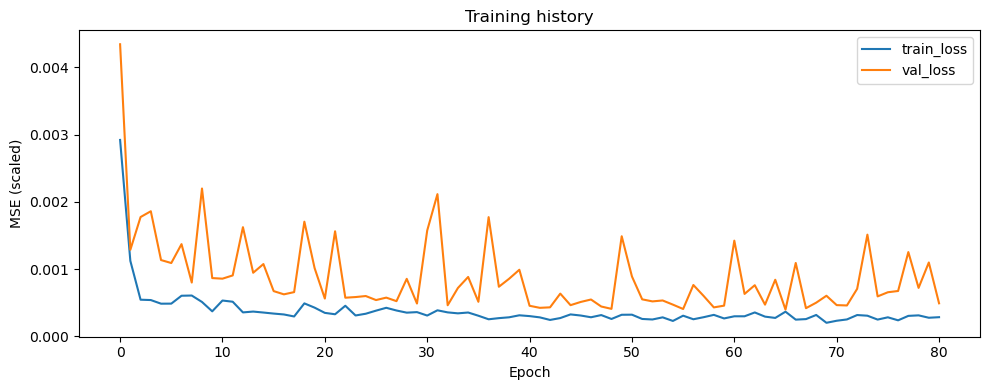

In [7]:
plt.figure(figsize=(10, 4))
plt.plot(history.history["loss"], label="train_loss")
plt.plot(history.history["val_loss"], label="val_loss")
plt.xlabel("Epoch")
plt.ylabel("MSE (scaled)")
plt.legend()
plt.title("Training history")
plt.tight_layout()
plt.show()

In [8]:
def mape(y_true, y_pred, eps=1e-8):
    y_true = np.asarray(y_true).ravel()
    y_pred = np.asarray(y_pred).ravel()
    return float(np.mean(np.abs((y_true - y_pred) / (np.abs(y_true) + eps))) * 100.0)


pred_test = model.predict(X_test, verbose=0)
y_test_usd = scaler.inverse_transform(y_test)
pred_usd = scaler.inverse_transform(pred_test)

mse = mean_squared_error(y_test_usd, pred_usd)
rmse = float(np.sqrt(mse))
mae = mean_absolute_error(y_test_usd, pred_usd)
mape_val = mape(y_test_usd, pred_usd)

print("--- Test set ---")
print(f"MSE:   {mse:,.2f} USD²")
print(f"RMSE:  {rmse:,.2f} USD")
print(f"MAE:   {mae:,.2f} USD")
print(f"MAPE:  {mape_val:.2f}%")

--- Test set ---
MSE:   111,750.93 USD²
RMSE:  334.29 USD
MAE:   269.13 USD
MAPE:  7.26%


Direction confusion matrix (rows=actual, cols=predicted): ['Down', 'Up']
[[ 0 87]
 [ 0 93]]
Saved: /Users/rishinatarajan/ACM Folder/ACM Research ForeQast/ForeQast/Layered GRU/layered_gru_direction_confusion_matrix.png


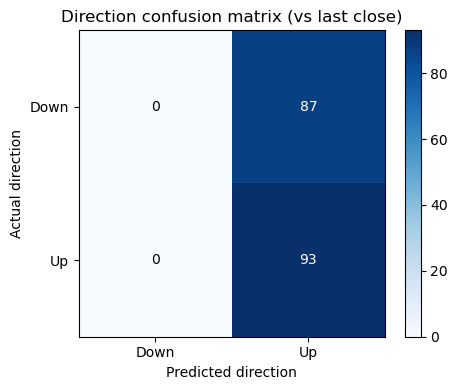

In [9]:
actual_up = (y_test_usd.ravel() - last_close_test.ravel()) > 0
pred_up = (pred_usd.ravel() - last_close_test.ravel()) > 0
dir_labels = ["Down", "Up"]
cm = confusion_matrix(actual_up.astype(int), pred_up.astype(int), labels=[0, 1])

print("Direction confusion matrix (rows=actual, cols=predicted):", dir_labels)
print(cm)

fig, ax = plt.subplots(figsize=(5, 4))
im = ax.imshow(cm, interpolation="nearest", cmap=plt.cm.Blues)
ax.figure.colorbar(im, ax=ax)
ax.set(
    xticks=np.arange(cm.shape[1]),
    yticks=np.arange(cm.shape[0]),
    xticklabels=dir_labels,
    yticklabels=dir_labels,
    ylabel="Actual direction",
    xlabel="Predicted direction",
    title="Direction confusion matrix (vs last close)",
)
thresh = cm.max() / 2.0 if cm.size else 0
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        ax.text(
            j,
            i,
            format(cm[i, j], "d"),
            ha="center",
            va="center",
            color="white" if cm[i, j] > thresh else "black",
        )
fig.tight_layout()
out_png = Path(CSV_PATH).parent / "layered_gru_direction_confusion_matrix.png"
fig.savefig(out_png, dpi=150)
print("Saved:", out_png)
plt.show()

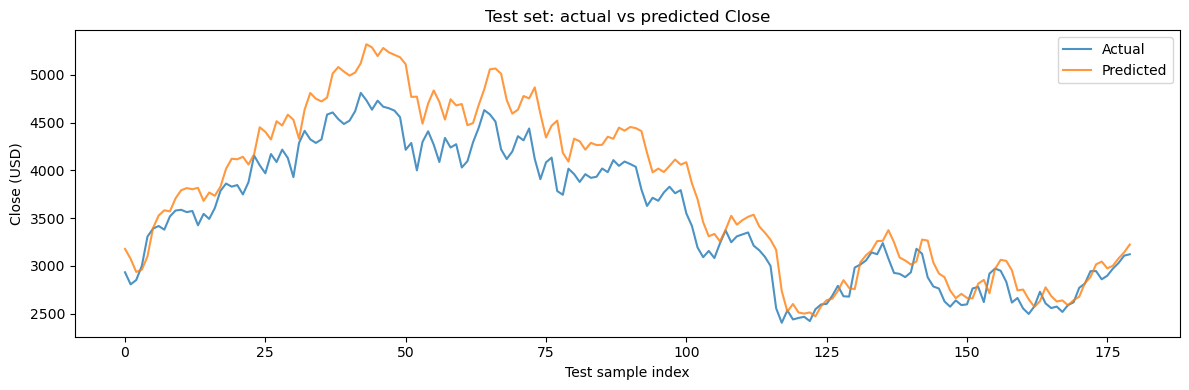

In [10]:
plt.figure(figsize=(12, 4))
plt.plot(y_test_usd, label="Actual", alpha=0.8)
plt.plot(pred_usd, label="Predicted", alpha=0.8)
plt.xlabel("Test sample index")
plt.ylabel("Close (USD)")
plt.legend()
plt.title("Test set: actual vs predicted Close")
plt.tight_layout()
plt.show()